In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize

In [2]:

def opt_min_var(prices: pd.DataFrame):
    rets = prices.pct_change().dropna()
    cov = rets.cov()
    var = lambda w: w.T @ cov @ w
    n_assets = len(prices.columns)
    w_0 = np.ones(n_assets) / n_assets
    restr = lambda w: sum(w) - 1
    rangos = [(0, 1)] * n_assets
    tol = 1e-32
    results = minimize(
        fun=var,
        x0=w_0,
        bounds=rangos,
        constraints={'fun': restr, 'type': 'eq'},
        tol=tol)

    return results.x
# MAX SHARPE

def opt_max_sharpe(price: pd.DataFrame, rf: float):
    rets = price.pct_change().dropna()
    cov = rets.cov()
    mu = rets.mean()
    sharpe = lambda w: -((sum(w*mu)-rf)/np.sqrt(w.T@cov@w))
    restr = lambda w: sum(w) - 1
    n_assets = len(price.columns)
    w_0 = np.ones(n_assets) / n_assets
    tol = 1e-32
    rangos = [(0,1)] * n_assets
    results = minimize(fun=sharpe,x0=w_0,bounds=rangos,constraints={'fun': restr, 'type': 'eq'},tol=tol)

    return results.x

# SEMIVAR TARJET


def opt_target_semivar(prices: pd.DataFrame, benchmark: pd.Series):
    rets = prices.pct_change().dropna()
    rets_benchmark = benchmark.pct_change().dropna()
    alpha = rets.sub(rets_benchmark.squeeze(),axis=0).dropna()
    below_zero_t = alpha[alpha<0].fillna(0)
    downside_risk_t = np.array(below_zero_t.std())
    corr = rets.corr()
    n_assets = len(prices.columns)
    semivar_matrix = (downside_risk_t.reshape(n_assets,1) @ downside_risk_t.reshape(1,n_assets))*corr
    func_target = lambda w: w.T @ semivar_matrix @ w
    restr = lambda w: sum(w)-1
    w_0 = np.ones(n_assets)/n_assets
    tol = 1e-16
    rangos = [(0,1)]*n_assets

    results = minimize(fun=func_target,x0=w_0,bounds=rangos,
                       constraints={'fun':restr,'type':'eq'},tol=tol)

    if not results.success:
        print(results.message)

    return results.x

# BACKTESTING
def static_backtesting(prices: pd.DataFrame, benchmark: pd.DataFrame, weights: dict, capital: float):

    rets=prices.pct_change().dropna()
    rets_b=benchmark.pct_change().dropna()
    evolucion=pd.DataFrame(index=rets.index)
    for strategy in weights.keys():

        if strategy =='Benchmark':
            evol_temp=rets_b+1
            evol_temp.iloc[0]=capital
            evol_temp=evol_temp.cumprod()
            evolucion[strategy]=evol_temp.values
        else:
            R_p=np.sum(rets * weights[strategy], axis=1)
            evol_temp=R_p+1
            evol_temp.iloc[0]=capital
            evol_temp=evol_temp.cumprod()
            evolucion[strategy]=evol_temp.values
    plt.figure(figsize=(12, 6))
    plt.plot(evolucion,label=evolucion.columns)
    plt.title('Backtesting')
    plt.xlabel('Date')
    plt.ylabel('Portafolio Value')
    plt.legend(evolucion.columns)
    plt.grid()

    return evolucion
#MAX OMEGA
def opt_max_omega(prices: pd.DataFrame):
    #Calcular los rendimientos
    rets = prices.pct_change().dropna()

    #Calcular downside y upside risk
    below_zero=rets[rets<0].fillna(0)
    above_zero=rets[rets>0].fillna(0)
    upside_risk=np.array(above_zero.std())
    downside_risk=np.array(below_zero.std())

    # Calcular Omega individual
    omega=upside_risk/downside_risk

    # Funcion
    func_omega=lambda w: -sum(w*omega)

    # Restricciones
    restr=lambda w: sum(w)-1

    # Valor Inicial
    n_assets=len(prices.columns)
    w_0=np.ones(n_assets)/n_assets

    # tol
    tol=1e-12

    # Rangos
    rangos=[(0,1)]*n_assets

    # optimización
    results=minimize(fun=func_omega,x0=w_0,bounds=rangos,
                     constraints={'fun':restr,'type':'eq'},tol=tol)

    if not results.success:
        print(results.message)

    return results.x


# 1.- Función de Métricas de Desempeño. (20%)

In [3]:

def performance_metrics(history, rf):

    rets = history.pct_change().dropna()

    metrics = pd.DataFrame(columns=history.columns)

    metrics.loc['Expected Return'] = rets.mean()*252

    metrics.loc['Volatility'] = rets.std()*np.sqrt(252)

    metrics.loc['Sharpe Ratio'] = (
        (metrics.loc['Expected Return']-rf) /
        metrics.loc['Volatility']
    )

    metrics.loc['Downside Risk'] = (
        rets[rets<0].fillna(0).std()*np.sqrt(252)
    )

    metrics.loc['Upside Risk'] = (
        rets[rets>0].fillna(0).std()*np.sqrt(252)
    )

    metrics.loc['Omega'] = (
        metrics.loc['Upside Risk'] /
        metrics.loc['Downside Risk']
    )

    metrics.loc['Beta'] = (
        rets.cov()['Benchmark'] /
        rets['Benchmark'].var()
    )

    metrics.loc['Jensen Alpha'] = (
        metrics.loc['Expected Return'] -
        (rf + metrics.loc['Beta'] *
        (metrics.loc['Expected Return']['Benchmark']-rf))
    )

    metrics.loc['Treynor'] = (
        (metrics.loc['Expected Return']-rf) /
        metrics.loc['Beta']
    )

    metrics.loc['Sortino'] = (
        (metrics.loc['Expected Return']-rf) /
        metrics.loc['Downside Risk']
    )

    return metrics



# 2.- Backtesting de Portafolio. (50%)

In [4]:
tickers=['LIVEPOLC-1.MX', 'KOFUBL.MX', 'CEMEXCPO.MX', 'CHDRAUIB.MX', 'CUERVO.MX', 'LABB.MX', 'RA.MX']
benchmark_ticker='^MXX'
rf=0.065
fecha_opt_inicio='2022-10-21'
fecha_bt_inicio='2024-10-21'
fecha_bt_fin='2026-10-22'
opt_data=yf.download(tickers+[benchmark_ticker],start=fecha_opt_inicio,end=fecha_bt_inicio,progress=False)['Close'].dropna()
opt_prices=opt_data[tickers]
benchmark_opt=opt_data[benchmark_ticker]
bt=yf.download(tickers+[benchmark_ticker],start=fecha_bt_inicio,end=fecha_bt_fin,progress=False)['Close'].dropna()
bt_prices=bt[tickers]
benchmark=bt[benchmark_ticker]

/var/folders/x9/60hcc2ln62d3r3xyv90d3wl40000gn/T/ipykernel_21700/3238957770.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  opt_data=yf.download(tickers+[benchmark_ticker],start=fecha_opt_inicio,end=fecha_bt_inicio,progress=False)['Close'].dropna()
/var/folders/x9/60hcc2ln62d3r3xyv90d3wl40000gn/T/ipykernel_21700/3238957770.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  bt=yf.download(tickers+[benchmark_ticker],start=fecha_bt_inicio,end=fecha_bt_fin,progress=False)['Close'].dropna()


In [5]:
w_min_var=opt_min_var(opt_prices)
w_max_sharpe=opt_max_sharpe(opt_prices,rf/252)
w_target_semivar=opt_target_semivar(opt_prices,benchmark_opt)
w_max_omega=opt_max_omega(opt_prices)


In [6]:
strategies={'Min Var':w_min_var,'Max Sharpe':w_max_sharpe,'Target Semivar':w_target_semivar,'Omega':w_max_omega,'Benchmark':1}

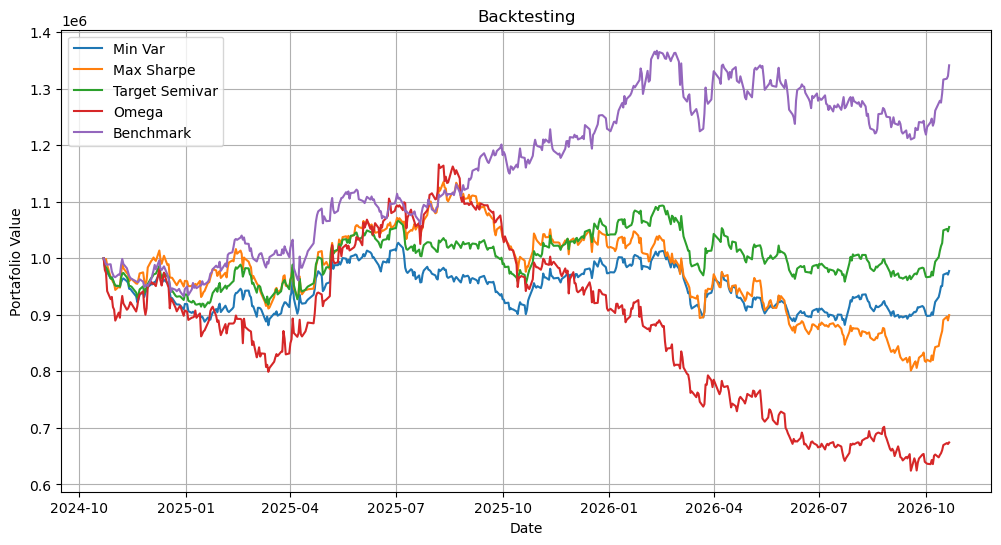

In [7]:
capital=1000000
evol=static_backtesting(bt_prices,benchmark,strategies,capital)

In [8]:
evol

,Min Var,Max Sharpe,Target Semivar,Omega,Benchmark
Date,,,,,
2024-10-22,1000000.000000,1000000.000000,1.000000e+06,1000000.000000,1.000000e+06
2024-10-23,985054.141802,990494.106307,9.872063e+05,979408.759509,9.956737e+05
2024-10-24,978274.691159,998787.672171,9.837959e+05,974099.316193,9.890558e+05
2024-10-25,975323.460556,987879.432279,9.804539e+05,942028.885196,9.888414e+05
2024-10-28,964612.663258,966917.886607,9.640590e+05,927751.381031,9.894519e+05
...,...,...,...,...,...
2026-10-15,950863.896223,871486.041266,1.026906e+06,660553.047628,1.292056e+06
2026-10-16,970908.637737,890897.833936,1.049458e+06,669550.779998,1.316239e+06
2026-10-19,973662.302014,896560.829056,1.051921e+06,673045.778673,1.317785e+06


In [9]:
metrics=performance_metrics(evol,rf)
metrics

,Min Var,Max Sharpe,Target Semivar,Omega,Benchmark
Expected Return,-0.001733,-0.038269,0.037197,-0.169722,1.611063e-01
Volatility,0.139839,0.174322,0.141906,0.240505,1.615776e-01
Sharpe Ratio,-0.477211,-0.592405,-0.195928,-0.975954,5.947997e-01
Downside Risk,0.080441,0.102624,0.081479,0.147784,9.077885e-02
Upside Risk,0.086115,0.103627,0.087383,0.141855,1.012297e-01
Omega,1.070528,1.009775,1.072465,0.959884,1.115124e+00
Beta,0.566914,0.722902,0.633637,0.648669,1.000000e+00
Jensen Alpha,-0.121217,-0.172745,-0.088700,-0.297063,-1.110223e-16
Treynor,-0.117712,-0.142854,-0.043879,-0.361852,9.610632e-02
Sortino,-0.829583,-1.006288,-0.341234,-1.588280,1.058686e+00


In [10]:
pesos=pd.DataFrame({'Min Var':w_min_var,'Max Sharpe':w_max_sharpe,'Target Semivar':w_target_semivar,'Omega':w_max_omega},index=opt_prices.columns)
pesos

,Min Var,Max Sharpe,Target Semivar,Omega
Ticker,,,,
LIVEPOLC-1.MX,0.246772,5.471336e-19,0.214663,6.592023e-17
KOFUBL.MX,0.249945,1.682524e-01,0.248511,4.718448e-16
CEMEXCPO.MX,0.024109,1.392754e-01,0.086390,0.000000e+00
CHDRAUIB.MX,0.185193,4.899180e-01,0.206529,1.000000e+00
CUERVO.MX,0.152443,2.212246e-17,0.083387,1.367401e-16
LABB.MX,0.066693,2.025543e-01,0.063344,1.387779e-16
RA.MX,0.074846,1.243004e-17,0.097176,1.053544e-17


### Interpretación de resultados

Al comparar las cinco estrategias podemos observar que el IPC México obtuvo los mejores resultados, con un rendimiento anualizado de 16.11% y un Sharpe de 0.595.

De las cuatro estrategias que optimizamos, Target Semivariance fue la que tuvo mejores resultados, con un rendimiento de 9.15% y un Sortino de 0.298, lo que nos indica que tuvo una mejor relación entre rendimiento y riesgo a la baja.

Por otro lado, Mínima Varianza fue la estrategia con menor volatilidad, aunque su rendimiento fue negativo. Máximo Sharpe tampoco obtuvo buenos resultados y Omega fue la que presentó mayores pérdidas y riesgo.

También podemos observar que todas tuvieron una Beta menor a 1 y un Alfa de Jensen negativo, por lo que ninguna logró superar el rendimiento requerido según el CAPM.

En general, considero que Target Semivariance fue la mejor de las cuatro estrategias optimizadas, aunque ninguna logró superar al IPC México.

# 3.- Selección de Estrategia de Inversión. (20%)

Yo elegiría la estrategia Target Semivariance, ya que considero importante tomar en cuenta principalmente el riesgo de obtener rendimientos negativos y buscar un buen rendimiento en relación con ese riesgo.

Aunque Mínima Varianza tuvo menor volatilidad, Target Semivariance obtuvo mejores resultados, con un rendimiento anualizado de 9.15% y un Sortino de 0.298. Además, fue la única de las cuatro estrategias que tuvo rendimientos positivos durante el backtesting.

Por eso considero que es la que mejor se adapta a mi perfil, ya que prefiero tener un equilibrio entre rendimiento y riesgo, tomando en cuenta principalmente las posibles pérdidas.

# 4.- Calculo de Pesos para Portafolio Real. (10%)

In [11]:
real_data=yf.download(tickers+[benchmark_ticker],
                      start='2024-10-23',end='2026-10-24',
                      progress=False)['Close'].dropna()

real_prices=real_data[tickers]
real_benchmark=real_data[benchmark_ticker]

w_real=opt_target_semivar(real_prices,real_benchmark)
dict(zip(real_prices.columns,w_real))

/var/folders/x9/60hcc2ln62d3r3xyv90d3wl40000gn/T/ipykernel_21700/3184167283.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  real_data=yf.download(tickers+[benchmark_ticker],


{'LIVEPOLC-1.MX': np.float64(0.2601734562605202),
 'KOFUBL.MX': np.float64(0.22591469689570437),
 'CEMEXCPO.MX': np.float64(0.14119936687508736),
 'CHDRAUIB.MX': np.float64(0.17156264001030772),
 'CUERVO.MX': np.float64(0.08503351265733837),
 'LABB.MX': np.float64(0.08467922180021133),
 'RA.MX': np.float64(0.031437105500830516)}

In [12]:
precios_actuales=real_prices.iloc[-1]
print('Última fecha:',real_prices.index[-1])
precios_actuales

Última fecha: 2026-10-23 00:00:00


Ticker
LIVEPOLC-1.MX    102.330002
KOFUBL.MX        220.860001
CEMEXCPO.MX       19.090000
CHDRAUIB.MX       90.910004
CUERVO.MX         16.320000
LABB.MX           15.260000
RA.MX            155.190002
Name: 2026-10-23 00:00:00, dtype: float64

In [13]:
pesos_reales=pd.Series(w_real,index=real_prices.columns)
capital_asignado=capital*pesos_reales
acciones=np.floor(capital_asignado/precios_actuales).astype(int)

portafolio_real=pd.DataFrame({
    'Peso':pesos_reales,
    'Precio':precios_actuales,
    'Capital asignado':capital_asignado,
    'Acciones':acciones,
    'Inversion':acciones*precios_actuales
})

print('Suma de ponderaciones:',pesos_reales.sum())
print('Capital invertido:',portafolio_real['Inversion'].sum())
print('Efectivo restante:',capital-portafolio_real['Inversion'].sum())

portafolio_real

Suma de ponderaciones: 1.0
Capital invertido: 999631.9234905243
Efectivo restante: 368.076509475708


,Peso,Precio,Capital asignado,Acciones,Inversion
Ticker,,,,,
LIVEPOLC-1.MX,0.260173,102.330002,260173.456261,2542,260122.864655
KOFUBL.MX,0.225915,220.860001,225914.696896,1022,225718.920624
CEMEXCPO.MX,0.141199,19.090000,141199.366875,7396,141189.641129
CHDRAUIB.MX,0.171563,90.910004,171562.640010,1887,171547.176910
CUERVO.MX,0.085034,16.320000,85033.512657,5210,85027.198410
LABB.MX,0.084679,15.260000,84679.221800,5549,84677.741270
RA.MX,0.031437,155.190002,31437.105501,202,31348.380493
